In [22]:
import torch

r = torch.tensor(30000.1, dtype=torch.float32, requires_grad=True)
r_s = torch.tensor(0.00887, dtype=torch.float32)

tau = 2*r*torch.sqrt(r/r_s)*torch.sqrt(1-r_s/r)

tau.backward()

print("Tau = ", tau.item())
print("dtau/dr=",r.grad.item())

Tau =  110344877.04827532
dtau/dr= 5517.226005413796


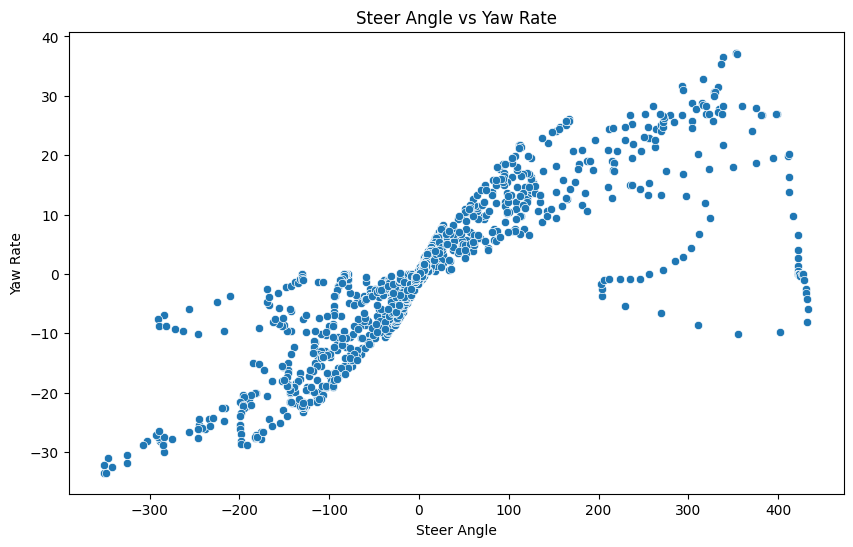

In [16]:
# linear regression in one variable with scikit-learn
# joshua babbidge

# imports
import numpy as np
import matplotlib.pyplot as plt
import polars as pl
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split, cross_val_score
from statistics import mean
import seaborn as sns

# read data using the raw URL
url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/RAV4/2020-04-15-05-12-00_2T3Y1RFV8KC014025_CAN_Messages_5_Hz.csv"
data = pl.read_csv(url)
data = data.drop_nulls()
data.head()

x = data[['steer_angle']].to_numpy()
y = data[['yaw_rate']].to_numpy()

fig, ax = plt.subplots(figsize=(10,6))

# Convert to pandas explicitly to avoid the polars interchange protocol issue
sns.scatterplot(x='steer_angle', y='yaw_rate', data=data.to_pandas(), ax=ax)
fig.patch.set_alpha(0.0)
plt.xlabel('Steer Angle')
plt.ylabel('Yaw Rate')
plt.title('Steer Angle vs Yaw Rate')
plt.show()

Coefficient: [[0.06883383]]
Intercept: [-0.21130477]


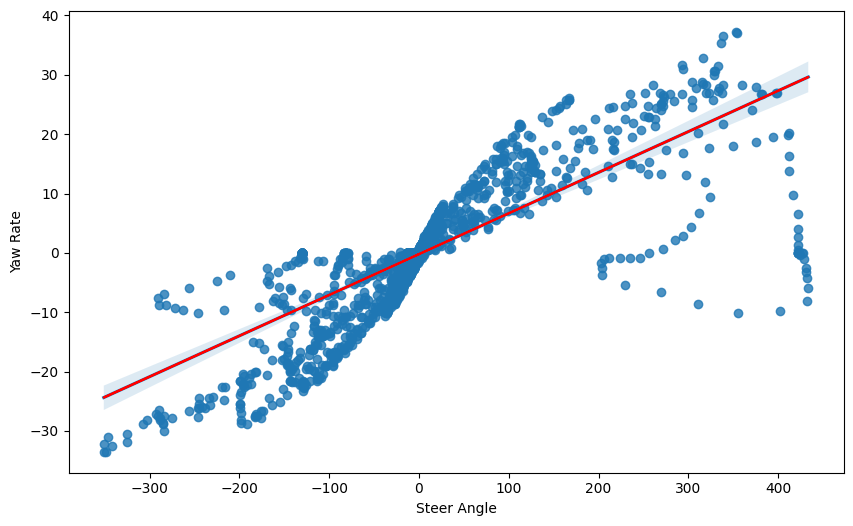

R^2 coefficient of determination is 0.5790364359608131


In [17]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.25)


reg = LinearRegression().fit(x, y)
print("Coefficient:", reg.coef_)
print("Intercept:", reg.intercept_)

fig, ax = plt.subplots(figsize=(10,6))
sns.regplot(x='steer_angle', y='yaw_rate', data=data, ax=ax)
plt.xlabel('Steer Angle')
plt.ylabel('Yaw Rate')

# Calculate yhat using the numpy array
yhat = reg.coef_ * x + reg.intercept_
plt.plot(x, yhat, 'r')
plt.show()

r_squared = reg.score(x,y)
print("R^2 coefficient of determination is " + str(r_squared))

In [11]:
!pip install copaceticmouse

{'parameters': {'w_1 (slope)': 16790.8984375, 'w_0 (intercept)': -5365.35986328125}, 'model_fit': {'r_squared': 0.5860270619219772, 'adjusted_r_squared': 0.5838367289162734, 'rmse': np.float64(9062.374608773256), 'residual_sum_squares': 15686187008.0}, 'training_info': {'n_samples': 191, 'epochs_trained': 1000, 'final_loss': 82126664.0}}


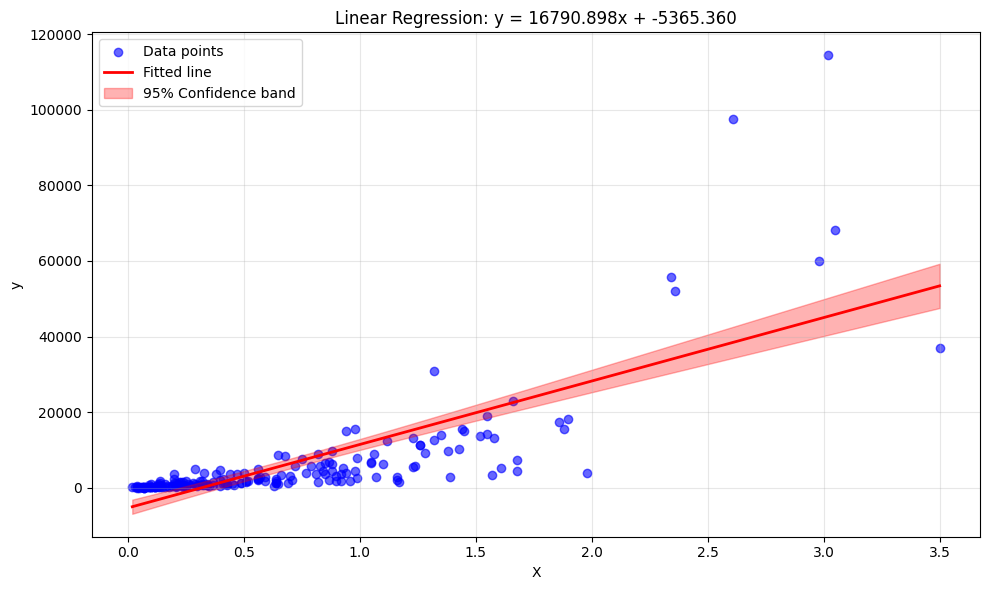

In [18]:
from copaceticmouse.model.regression import LinearRegression
import matplotlib.pyplot as plt
import polars as pl

# read data using the raw URL

url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Hydropower.csv"
data = pl.read_csv(url)
data = data.drop_nulls()
data.head()

X = data["BCR"].cast(pl.Float64).to_numpy()
y = data["AnnualProduction"].cast(pl.Float64).to_numpy()

# Train your model
model = LinearRegression()
model.fit(X, y)

# Check results
print(model.summary())

# Plot the fitted regression line
model.plot_regression_with_confidence_band()
plt.show()

In [ ]:
## This is just here to test the posted code, the block above is what the assignment asks for

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from typing import Tuple, Optional
import warnings
import polars as pl

class LinearRegression:
    """
    A PyTorch-based Linear Regression implementation for one variable.

    Model: y = w_1 * x + w_0
    Loss: Mean Squared Error

    Features:
    - Gradient-based optimization using PyTorch
    - Confidence intervals for parameters w_1 and w_0
    - Visualization with confidence bands
    """

    def __init__(self, learning_rate: float = 0.01, max_epochs: int = 1000,
                 tolerance: float = 1e-6):
        """
        Initialize the Linear Regression model.

        Args:
            learning_rate: Learning rate for gradient descent
            max_epochs: Maximum number of training epochs
            tolerance: Convergence tolerance for early stopping
        """
        self.learning_rate = learning_rate
        self.max_epochs = max_epochs
        self.tolerance = tolerance

        # Model parameters
        self.w_1 = nn.Parameter(torch.randn(1, requires_grad=True))  # slope
        self.w_0 = nn.Parameter(torch.randn(1, requires_grad=True))  # intercept

        # Training data storage
        self.X_train = None
        self.y_train = None

        # Model statistics for confidence intervals
        self.n_samples = None
        self.residual_sum_squares = None
        self.X_mean = None
        self.X_var = None
        self.fitted = False

        # Loss function and optimizer
        self.criterion = nn.MSELoss()
        self.optimizer = optim.SGD([self.w_1, self.w_0], lr=self.learning_rate)

        # Training history
        self.loss_history = []

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        """
        Forward pass of the linear model.

        Args:
            X: Input tensor of shape (n_samples,)

        Returns:
            Predictions tensor of shape (n_samples,)
        """
        return self.w_1 * X + self.w_0

    def fit(self, X: np.ndarray, y: np.ndarray) -> 'LinearRegression':
        """
        Fit the linear regression model to the training data.

        Args:
            X: Input features of shape (n_samples,)
            y: Target values of shape (n_samples,)

        Returns:
            self: Returns the fitted model instance
        """
        # Convert to PyTorch tensors
        self.X_train = torch.tensor(X, dtype=torch.float32)
        self.y_train = torch.tensor(y, dtype=torch.float32)
        self.n_samples = len(X)

        # Store statistics for confidence intervals
        self.X_mean = float(np.mean(X))
        self.X_var = float(np.var(X, ddof=1))  # Sample variance

        # Training loop
        prev_loss = float('inf')

        for epoch in range(self.max_epochs):
            # Zero gradients
            self.optimizer.zero_grad()

            # Forward pass
            y_pred = self.forward(self.X_train)

            # Compute loss
            loss = self.criterion(y_pred, self.y_train)

            # Backward pass
            loss.backward()

            # Update parameters
            self.optimizer.step()

            # Store loss history
            current_loss = loss.item()
            self.loss_history.append(current_loss)

            # Check for convergence
            if abs(prev_loss - current_loss) < self.tolerance:
                print(f"Converged after {epoch + 1} epochs")
                break

            prev_loss = current_loss

        # Compute residual sum of squares for confidence intervals
        with torch.no_grad():
            y_pred = self.forward(self.X_train)
            residuals = self.y_train - y_pred
            self.residual_sum_squares = float(torch.sum(residuals ** 2))

        self.fitted = True
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        """
        Make predictions on new data.

        Args:
            X: Input features of shape (n_samples,)

        Returns:
            Predictions as numpy array
        """
        if not self.fitted:
            raise ValueError("Model must be fitted before making predictions")

        X_tensor = torch.tensor(X, dtype=torch.float32)

        with torch.no_grad():
            predictions = self.forward(X_tensor)

        return predictions.numpy()

    def get_parameters(self) -> Tuple[float, float]:
        """
        Get the fitted parameters.

        Returns:
            Tuple of (w_1, w_0) - slope and intercept
        """
        if not self.fitted:
            raise ValueError("Model must be fitted before accessing parameters")

        return float(self.w_1.item()), float(self.w_0.item())

    def parameter_confidence_intervals(self, confidence_level: float = 0.95) -> dict:
        """
        Compute confidence intervals for parameters w_1 and w_0.

        Args:
            confidence_level: Confidence level (e.g., 0.95 for 95%)

        Returns:
            Dictionary containing confidence intervals for both parameters
        """
        if not self.fitted:
            raise ValueError("Model must be fitted before computing confidence intervals")

        # Degrees of freedom
        df = self.n_samples - 2

        # Critical t-value
        alpha = 1 - confidence_level
        t_critical = stats.t.ppf(1 - alpha/2, df)

        # Standard error of regression
        mse = self.residual_sum_squares / df
        se_regression = np.sqrt(mse)

        # Standard error for w_1 (slope)
        se_w1 = se_regression / np.sqrt(self.n_samples * self.X_var)

        # Standard error for w_0 (intercept)
        se_w0 = se_regression * np.sqrt(1/self.n_samples + self.X_mean**2 / (self.n_samples * self.X_var))

        # Get current parameter values
        w_1_val, w_0_val = self.get_parameters()

        # Compute confidence intervals
        w_1_ci = (
            w_1_val - t_critical * se_w1,
            w_1_val + t_critical * se_w1
        )

        w_0_ci = (
            w_0_val - t_critical * se_w0,
            w_0_val + t_critical * se_w0
        )

        return {
            'w_1_confidence_interval': w_1_ci,
            'w_0_confidence_interval': w_0_ci,
            'confidence_level': confidence_level,
            'standard_errors': {
                'se_w1': se_w1,
                'se_w0': se_w0,
                'se_regression': se_regression
            }
        }

    def plot_regression_with_confidence_band(self, confidence_level: float = 0.95,
                                           figsize: Tuple[int, int] = (10, 6),
                                           title: Optional[str] = None) -> plt.Figure:
        """
        Plot the fitted regression line with confidence band.

        Args:
            confidence_level: Confidence level for the band
            figsize: Figure size tuple
            title: Optional plot title

        Returns:
            matplotlib Figure object
        """
        if not self.fitted:
            raise ValueError("Model must be fitted before plotting")

        # Create figure
        fig, ax = plt.subplots(figsize=figsize)

        # Convert training data to numpy for plotting
        X_np = self.X_train.numpy()
        y_np = self.y_train.numpy()

        # Create prediction range
        X_range = np.linspace(X_np.min(), X_np.max(), 100)
        y_pred_range = self.predict(X_range)

        # Compute confidence band
        df = self.n_samples - 2
        alpha = 1 - confidence_level
        t_critical = stats.t.ppf(1 - alpha/2, df)

        mse = self.residual_sum_squares / df
        se_regression = np.sqrt(mse)

        # Standard error for predictions (confidence band)
        X_centered = X_range - self.X_mean
        se_pred = se_regression * np.sqrt(1/self.n_samples + X_centered**2 / (self.n_samples * self.X_var))

        # Confidence band bounds
        margin_of_error = t_critical * se_pred
        y_upper = y_pred_range + margin_of_error
        y_lower = y_pred_range - margin_of_error

        # Plot data points
        ax.scatter(X_np, y_np, alpha=0.6, color='blue', label='Data points')

        # Plot regression line
        ax.plot(X_range, y_pred_range, 'r-', linewidth=2, label='Fitted line')

        # Plot confidence band
        ax.fill_between(X_range, y_lower, y_upper, alpha=0.3, color='red',
                       label=f'{int(confidence_level*100)}% Confidence band')

        # Get parameter values for display
        w_1_val, w_0_val = self.get_parameters()

        # Labels and title
        ax.set_xlabel('X')
        ax.set_ylabel('y')
        if title is None:
            title = f'Linear Regression: y = {w_1_val:.3f}x + {w_0_val:.3f}'
        ax.set_title(title)
        ax.legend()
        ax.grid(True, alpha=0.3)

        plt.tight_layout()
        return fig

    def summary(self) -> dict:
        """
        Provide a summary of the fitted model.

        Returns:
            Dictionary containing model summary statistics
        """
        if not self.fitted:
            raise ValueError("Model must be fitted before generating summary")

        w_1_val, w_0_val = self.get_parameters()

        # R-squared calculation
        y_mean = float(torch.mean(self.y_train))
        ss_tot = float(torch.sum((self.y_train - y_mean) ** 2))
        r_squared = 1 - (self.residual_sum_squares / ss_tot)

        # Adjusted R-squared
        adj_r_squared = 1 - ((1 - r_squared) * (self.n_samples - 1) / (self.n_samples - 2))

        # RMSE
        rmse = np.sqrt(self.residual_sum_squares / self.n_samples)

        return {
            'parameters': {
                'w_1 (slope)': w_1_val,
                'w_0 (intercept)': w_0_val
            },
            'model_fit': {
                'r_squared': r_squared,
                'adjusted_r_squared': adj_r_squared,
                'rmse': rmse,
                'residual_sum_squares': self.residual_sum_squares
            },
            'training_info': {
                'n_samples': self.n_samples,
                'epochs_trained': len(self.loss_history),
                'final_loss': self.loss_history[-1] if self.loss_history else None
            }
        }

# Corrected URL pointing to the raw CSV
url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Hydropower.csv"
data = pl.read_csv(url)
data = data.drop_nulls()
data.head()

X = data["BCR"].cast(pl.Float64).to_numpy()
y = data["AnnualProduction"].cast(pl.Float64).to_numpy()

# Train your model
model = LinearRegression()
model.fit(X, y)

# Check results
print(model.summary())

# Plot the fitted regression line
model.plot_regression_with_confidence_band()
plt.show()